# Predição de AVC — Análise Exploratória de Dados

**Projeto de Redes Neurais e Deep Learning · Entrega 1 (EDA)**  
**Tarefa:** classificação binária · **Alvo:** `stroke` · **Seed:** 42  
**Equipe:** Eduardo Takei Yaginuma  
**Fonte:** [Stroke Prediction Dataset — Kaggle](https://www.kaggle.com/datasets/fedesoriano/stroke-prediction-dataset)

> **Objetivo.** Entender a qualidade, as distribuições e as relações da base; identificar riscos para a classificação; e terminar com um pré-processamento reproduzível, ajustado somente no treino e pronto para uma rede neural. **Nenhum modelo preditivo é treinado nesta entrega.**

> **Pré-requisito administrativo.** A proposta/base deve estar aprovada pelo professor. O conjunto atende ao perfil sugerido no enunciado (tabular, público, mais de 1.000 instâncias, variáveis numéricas e categóricas e alvo no arquivo), mas a aprovação da equipe continua sendo obrigatória.

**Uso de IA:** OpenAI Codex foi usado como apoio de implementação e revisão. A equipe é responsável por verificar e explicar cada decisão e resultado.

## 0. Proposta e reprodutibilidade

O problema é estimar, a partir de características demográficas e clínicas, se uma pessoa pertence à classe com registro de AVC (`stroke=1`). A motivação é estudar uma classificação rara e assimétrica, situação em que acurácia isolada seria enganosa. O primeiro risco é o forte desbalanceamento; riscos adicionais são a procedência clínica não documentada, dados ausentes em IMC e possíveis extremos.

O Kaggle informa apenas **“confidential source”** e uso educacional. Portanto, os resultados deste notebook são exploratórios e **não validam uso clínico**. O download é feito pela API pública do Kaggle e o SHA-256 evita analisar silenciosamente outra versão do arquivo.

In [1]:
from __future__ import annotations

import hashlib
import io
import inspect
import sys
import urllib.request
import warnings
import zipfile
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import Markdown, display
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE, trustworthiness
from sklearn.metrics import silhouette_score
from sklearn.model_selection import train_test_split

warnings.filterwarnings("ignore", message="IProgress not found.*")
try:
    import umap.umap_ as umap
except ImportError as exc:
    raise ImportError("Instale as dependências com: pip install -r requirements.txt") from exc

SEED = 42
np.random.seed(SEED)
warnings.filterwarnings("ignore", category=FutureWarning)

sns.set_theme(style="whitegrid", context="notebook", palette="colorblind")
plt.rcParams.update({"figure.dpi": 110, "axes.titleweight": "bold"})

# Funciona ao executar da raiz do repositório ou da pasta do notebook.
cwd = Path.cwd().resolve()
PROJECT_DIR = cwd if (cwd / "dataset.ipynb").exists() else cwd / "project" / "Delivery-1-EDA"
if not PROJECT_DIR.exists():
    raise FileNotFoundError("Execute a partir da raiz do repositório ou de project/Delivery-1-EDA.")
sys.path.insert(0, str(PROJECT_DIR / "code"))

from preprocessing import (  # noqa: E402
    CATEGORICAL_FEATURES,
    NUMERIC_FEATURES,
    build_preprocessor,
)

TARGET = "stroke"
ID_COLUMN = "id"
DATA_URL = "https://www.kaggle.com/api/v1/datasets/download/fedesoriano/stroke-prediction-dataset"
EXPECTED_SHA256 = "644d473b05d2797006bd94865e4f8bb057f0c721617911613c82c8fcfc707420"
DATA_DIR = PROJECT_DIR / "data"
CSV_PATH = DATA_DIR / "healthcare-dataset-stroke-data.csv"

def obtain_data(path: Path = CSV_PATH) -> Path:
    '''Baixa e valida a versão analisada; reutiliza o cache nas próximas execuções.'''
    if not path.exists():
        DATA_DIR.mkdir(parents=True, exist_ok=True)
        request = urllib.request.Request(DATA_URL, headers={"User-Agent": "Mozilla/5.0"})
        with urllib.request.urlopen(request, timeout=60) as response:
            archive = zipfile.ZipFile(io.BytesIO(response.read()))
        payload = archive.read("healthcare-dataset-stroke-data.csv")
        path.write_bytes(payload)
    digest = hashlib.sha256(path.read_bytes()).hexdigest()
    if digest != EXPECTED_SHA256:
        raise ValueError(f"Versão inesperada do arquivo: SHA-256={digest}")
    return path

data_path = obtain_data()
df = pd.read_csv(data_path, na_values=["N/A"])
expected_columns = {
    "id", "gender", "age", "hypertension", "heart_disease", "ever_married",
    "work_type", "Residence_type", "avg_glucose_level", "bmi",
    "smoking_status", "stroke",
}
assert set(df.columns) == expected_columns and df.shape == (5110, 12)

print(f"Arquivo: {data_path}")
print(f"SHA-256: {EXPECTED_SHA256}")
print(f"Dimensão bruta validada: {df.shape[0]:,} linhas × {df.shape[1]} colunas")
df.head()

Arquivo: /Users/eduardoyaginuma/Documents/Repositorios/insper/neural-networks/project/Delivery-1-EDA/data/healthcare-dataset-stroke-data.csv
SHA-256: 644d473b05d2797006bd94865e4f8bb057f0c721617911613c82c8fcfc707420
Dimensão bruta validada: 5,110 linhas × 12 colunas


,id,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke
0,9046,Male,67.0,0,1,Yes,Private,Urban,228.69,36.6,formerly smoked,1
1,51676,Female,61.0,0,0,Yes,Self-employed,Rural,202.21,NaN,never smoked,1
2,31112,Male,80.0,0,1,Yes,Private,Rural,105.92,32.5,never smoked,1
3,60182,Female,49.0,0,0,Yes,Private,Urban,171.23,34.4,smokes,1
4,1665,Female,79.0,1,0,Yes,Self-employed,Rural,174.12,24.0,never smoked,1


## 1. Inspeção inicial

### 1A. Dicionário de dados

Cada linha representa uma pessoa/paciente. A documentação do Kaggle não informa período, país, método de amostragem nem protocolo de medição; por isso, não se deve presumir representatividade populacional.

In [2]:
dictionary = pd.DataFrame([
    ("id", "identificador único", "inteiro", "sem unidade", "identificador; excluir"),
    ("gender", "gênero informado", "categórica nominal", "Female/Male/Other", "preditora"),
    ("age", "idade", "numérica contínua", "anos", "preditora"),
    ("hypertension", "diagnóstico de hipertensão", "categórica binária", "0=não; 1=sim", "preditora"),
    ("heart_disease", "diagnóstico de doença cardíaca", "categórica binária", "0=não; 1=sim", "preditora"),
    ("ever_married", "já se casou", "categórica binária", "No/Yes", "preditora"),
    ("work_type", "tipo de trabalho", "categórica nominal", "5 categorias", "preditora"),
    ("Residence_type", "tipo de residência", "categórica nominal", "Rural/Urban", "preditora"),
    ("avg_glucose_level", "nível médio de glicose no sangue", "numérica contínua", "não informada", "preditora"),
    ("bmi", "índice de massa corporal", "numérica contínua", "kg/m²", "preditora"),
    ("smoking_status", "situação de tabagismo", "categórica nominal", "4 categorias", "preditora"),
    ("stroke", "registro de AVC", "categórica binária", "0=não; 1=sim", "alvo"),
], columns=["Variável", "Significado", "Tipo analítico", "Unidade/codificação", "Papel"])
display(Markdown("**Tabela 1 — Dicionário completo das 12 colunas.**"))
display(dictionary)

**Tabela 1 — Dicionário completo das 12 colunas.**

,Variável,Significado,Tipo analítico,Unidade/codificação,Papel
0,id,identificador único,inteiro,sem unidade,identificador; excluir
1,gender,gênero informado,categórica nominal,Female/Male/Other,preditora
2,age,idade,numérica contínua,anos,preditora
3,hypertension,diagnóstico de hipertensão,categórica binária,0=não; 1=sim,preditora
4,heart_disease,diagnóstico de doença cardíaca,categórica binária,0=não; 1=sim,preditora
5,ever_married,já se casou,categórica binária,No/Yes,preditora
6,work_type,tipo de trabalho,categórica nominal,5 categorias,preditora
7,Residence_type,tipo de residência,categórica nominal,Rural/Urban,preditora
8,avg_glucose_level,nível médio de glicose no sangue,numérica contínua,não informada,preditora
9,bmi,índice de massa corporal,numérica contínua,kg/m²,preditora


### 1B. Qualidade

In [3]:
missing = pd.DataFrame({
    "ausentes_n": df.isna().sum(),
    "ausentes_%": 100 * df.isna().mean(),
}).sort_values(["ausentes_n", "ausentes_%"], ascending=False)

allowed = {
    "gender": {"Female", "Male", "Other"},
    "hypertension": {0, 1},
    "heart_disease": {0, 1},
    "ever_married": {"No", "Yes"},
    "work_type": {"children", "Govt_job", "Never_worked", "Private", "Self-employed"},
    "Residence_type": {"Rural", "Urban"},
    "smoking_status": {"formerly smoked", "never smoked", "smokes", "Unknown"},
    "stroke": {0, 1},
}
unexpected = {col: int((~df[col].isin(values)).sum()) for col, values in allowed.items()}
impossible = pd.Series({
    "age fora de [0, 120]": int((~df["age"].between(0, 120)).sum()),
    "glicose <= 0": int((df["avg_glucose_level"] <= 0).sum()),
    "bmi <= 0": int((df["bmi"] <= 0).sum()),
    "categorias fora do dicionário": sum(unexpected.values()),
}, name="linhas")

display(Markdown("**Tabela 2 — Ausência por coluna (contagem e porcentagem).**"))
display(missing.style.format({"ausentes_%": "{:.2f}%"}))
display(Markdown("**Checagens de consistência e duplicidade.**"))
display(impossible.to_frame())

n_full_duplicates = int(df.duplicated().sum())
n_semantic_duplicates = int(df.drop(columns=ID_COLUMN).duplicated().sum())
n_duplicate_ids = int(df[ID_COLUMN].duplicated().sum())
n_other = int((df["gender"] == "Other").sum())

display(Markdown(f'''
**Leitura da qualidade.** `bmi` concentra **{missing.loc['bmi', 'ausentes_n']:.0f} ausências ({missing.loc['bmi', 'ausentes_%']:.2f}%)**; nenhuma outra coluna tem `NaN`. Há **{n_full_duplicates} duplicatas exatas**, **{n_semantic_duplicates} duplicatas desconsiderando `id`** e **{n_duplicate_ids} IDs repetidos**. As regras de domínio acima encontraram **{int(impossible.sum())} valores impossíveis/inconsistentes**. `gender="Other"` aparece em **{n_other} linha**: é rara, mas prevista no dicionário, portanto será preservada. `smoking_status="Unknown"` significa informação indisponível segundo a fonte; será mantida como categoria explícita, não confundida com `NaN`.

**Coluna descartada.** `id` é único em {df[ID_COLUMN].nunique():,}/{len(df):,} linhas, não mede uma característica do paciente e pode induzir memorização. Ela será removida antes da modelagem. Nenhuma variável pós-desfecho foi identificada, mas a documentação limitada não permite excluir vazamento de coleta; esse risco permanece registrado.
'''))

**Tabela 2 — Ausência por coluna (contagem e porcentagem).**

,ausentes_n,ausentes_%
bmi,201,3.93%
id,0,0.00%
gender,0,0.00%
age,0,0.00%
hypertension,0,0.00%
heart_disease,0,0.00%
ever_married,0,0.00%
work_type,0,0.00%
Residence_type,0,0.00%
avg_glucose_level,0,0.00%


**Checagens de consistência e duplicidade.**

,linhas
"age fora de [0, 120]",0
glicose <= 0,0
bmi <= 0,0
categorias fora do dicionário,0



**Leitura da qualidade.** `bmi` concentra **201 ausências (3.93%)**; nenhuma outra coluna tem `NaN`. Há **0 duplicatas exatas**, **0 duplicatas desconsiderando `id`** e **0 IDs repetidos**. As regras de domínio acima encontraram **0 valores impossíveis/inconsistentes**. `gender="Other"` aparece em **1 linha**: é rara, mas prevista no dicionário, portanto será preservada. `smoking_status="Unknown"` significa informação indisponível segundo a fonte; será mantida como categoria explícita, não confundida com `NaN`.

**Coluna descartada.** `id` é único em 5,110/5,110 linhas, não mede uma característica do paciente e pode induzir memorização. Ela será removida antes da modelagem. Nenhuma variável pós-desfecho foi identificada, mas a documentação limitada não permite excluir vazamento de coleta; esse risco permanece registrado.


### 1C. Alvo

**Tabela 3 — Distribuição do alvo.**

,n,%
stroke,,
0,4861,95.13%
1,249,4.87%


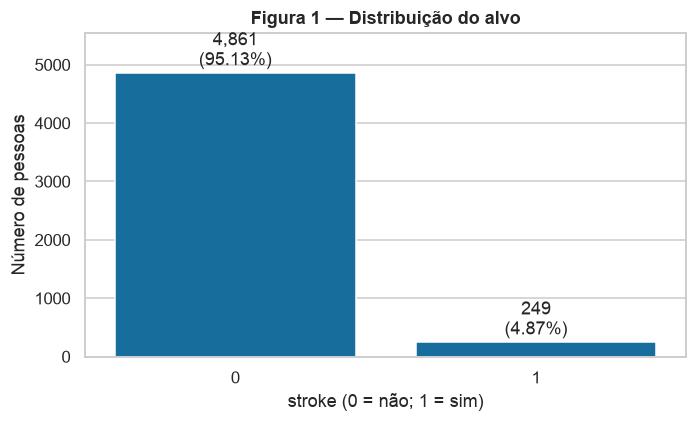

**Conclusão da Figura 1.** A classe positiva reúne **249 pessoas (4.87%)**, contra **4,861 negativas** — razão de **1:19.52**. Na etapa de modelagem, o split deve ser estratificado e a avaliação deve priorizar PR-AUC, recall, precisão e matriz de confusão, não acurácia isolada.

In [4]:
target_table = df[TARGET].value_counts().sort_index().rename_axis("stroke").to_frame("n")
target_table["%"] = 100 * target_table["n"] / len(df)
display(Markdown("**Tabela 3 — Distribuição do alvo.**"))
display(target_table.style.format({"%": "{:.2f}%"}))

fig, ax = plt.subplots(figsize=(6.5, 4))
sns.barplot(x=target_table.index.astype(str), y=target_table["n"], ax=ax)
for patch, (_, row) in zip(ax.patches, target_table.iterrows()):
    ax.text(patch.get_x() + patch.get_width()/2, patch.get_height() + 40,
            f"{int(row['n']):,}\n({row['%']:.2f}%)", ha="center", va="bottom")
ax.set(title="Figura 1 — Distribuição do alvo", xlabel="stroke (0 = não; 1 = sim)", ylabel="Número de pessoas")
ax.set_ylim(0, target_table["n"].max() * 1.14)
plt.tight_layout()
plt.show()

minority_pct = 100 * df[TARGET].mean()
imbalance_ratio = (df[TARGET] == 0).sum() / (df[TARGET] == 1).sum()
display(Markdown(f'''**Conclusão da Figura 1.** A classe positiva reúne **{(df[TARGET] == 1).sum():,} pessoas ({minority_pct:.2f}%)**, contra **{(df[TARGET] == 0).sum():,} negativas** — razão de **1:{imbalance_ratio:.2f}**. Na etapa de modelagem, o split deve ser estratificado e a avaliação deve priorizar PR-AUC, recall, precisão e matriz de confusão, não acurácia isolada.'''))

### 1D. Separação treino/teste

In [5]:
# O split ocorre antes de qualquer imputação, clipping, codificação ou escala.
X = df.drop(columns=[TARGET, ID_COLUMN]).copy()
y = df[TARGET].astype("int8").copy()

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=SEED, stratify=y
)

split_table = pd.DataFrame({
    "partição": ["treino", "teste"],
    "linhas": [len(X_train), len(X_test)],
    "positivos": [int(y_train.sum()), int(y_test.sum())],
    "positivos_%": [100*y_train.mean(), 100*y_test.mean()],
})
display(split_table.style.format({"positivos_%": "{:.2f}%"}))
display(Markdown(f'''
Com `random_state=42`, o split estratificado 80/20 produziu **{len(X_train):,} linhas de treino** e **{len(X_test):,} de teste**. As taxas positivas são **{100*y_train.mean():.2f}%** e **{100*y_test.mean():.2f}%**, respectivamente. Daqui em diante, toda estatística que define transformação é estimada exclusivamente em `X_train`; o teste permanece reservado.
'''))

assert set(X_train.index).isdisjoint(X_test.index)
assert len(X_train) + len(X_test) == len(df)

,partição,linhas,positivos,positivos_%
0,treino,4088,199,4.87%
1,teste,1022,50,4.89%



Com `random_state=42`, o split estratificado 80/20 produziu **4,088 linhas de treino** e **1,022 de teste**. As taxas positivas são **4.87%** e **4.89%**, respectivamente. Daqui em diante, toda estatística que define transformação é estimada exclusivamente em `X_train`; o teste permanece reservado.


## 2. Análise univariada — somente treino

### 2A. Variáveis numéricas

In [6]:
numeric_summary = X_train[NUMERIC_FEATURES].describe(percentiles=[.25, .5, .75]).T
numeric_summary = numeric_summary.rename(columns={"25%": "Q1", "50%": "mediana", "75%": "Q3"})
numeric_summary["ausentes"] = X_train[NUMERIC_FEATURES].isna().sum()
numeric_summary["assimetria"] = X_train[NUMERIC_FEATURES].skew()
numeric_summary["IQR"] = numeric_summary["Q3"] - numeric_summary["Q1"]
numeric_summary = numeric_summary[["count", "ausentes", "mean", "mediana", "std", "min", "Q1", "Q3", "max", "IQR", "assimetria"]]
display(Markdown("**Tabela 4 — Estatísticas descritivas de todas as variáveis numéricas no treino.**"))
display(numeric_summary.style.format("{:.2f}"))

**Tabela 4 — Estatísticas descritivas de todas as variáveis numéricas no treino.**

,count,ausentes,mean,mediana,std,min,Q1,Q3,max,IQR,assimetria
age,4088.00,0.00,43.35,45.00,22.60,0.08,26.00,61.00,82.00,35.00,-0.16
avg_glucose_level,4088.00,0.00,106.32,91.94,45.26,55.12,77.31,114.20,271.74,36.89,1.56
bmi,3918.00,170.00,28.92,28.00,7.93,10.30,23.60,33.10,97.60,9.50,1.12


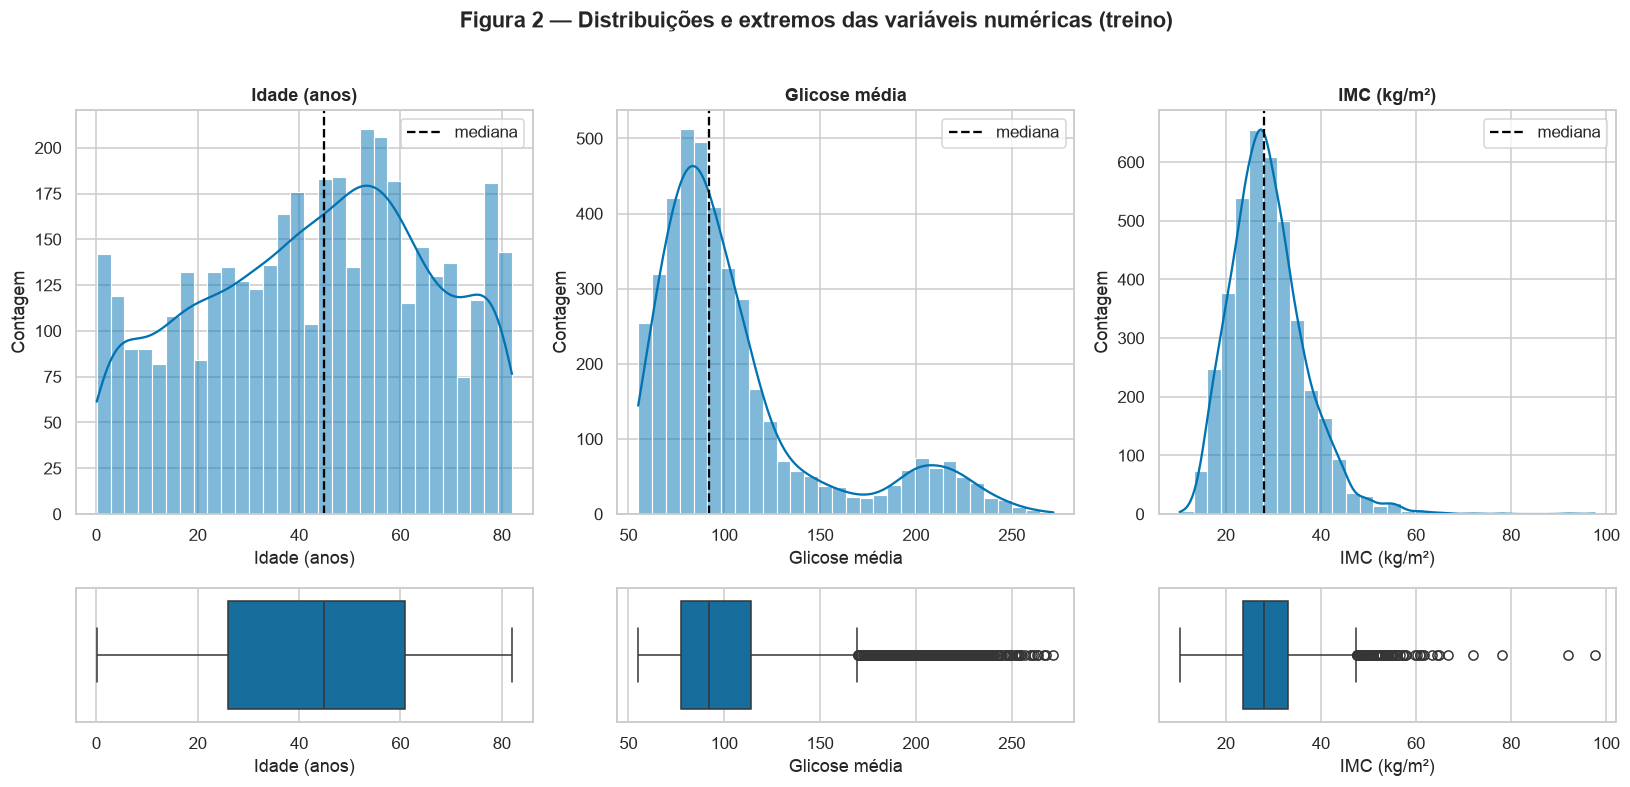


**Conclusão da Figura 2.** `age` é quase simétrica (assimetria **-0.16**) e cobre infância a velhice, sem extremos pela regra de Tukey. `avg_glucose_level` é fortemente assimétrica à direita (**1.56**) e tem uma segunda concentração em valores altos. `bmi` também tem cauda direita (**1.12**) e extremos visíveis até **97.6 kg/m²**. Isso motiva imputação mediana, clipping robusto e padronização ajustados no treino.


In [7]:
fig, axes = plt.subplots(2, 3, figsize=(15, 7), gridspec_kw={"height_ratios": [3, 1]})
labels = {"age": "Idade (anos)", "avg_glucose_level": "Glicose média", "bmi": "IMC (kg/m²)"}
for j, col in enumerate(NUMERIC_FEATURES):
    sns.histplot(X_train[col], kde=True, bins=30, ax=axes[0, j])
    axes[0, j].axvline(X_train[col].median(), color="black", ls="--", label="mediana")
    axes[0, j].set(title=labels[col], xlabel=labels[col], ylabel="Contagem")
    axes[0, j].legend()
    sns.boxplot(x=X_train[col], ax=axes[1, j])
    axes[1, j].set(xlabel=labels[col], ylabel="")
fig.suptitle("Figura 2 — Distribuições e extremos das variáveis numéricas (treino)", y=1.02, fontweight="bold")
plt.tight_layout()
plt.show()

display(Markdown(f'''
**Conclusão da Figura 2.** `age` é quase simétrica (assimetria **{numeric_summary.loc['age', 'assimetria']:.2f}**) e cobre infância a velhice, sem extremos pela regra de Tukey. `avg_glucose_level` é fortemente assimétrica à direita (**{numeric_summary.loc['avg_glucose_level', 'assimetria']:.2f}**) e tem uma segunda concentração em valores altos. `bmi` também tem cauda direita (**{numeric_summary.loc['bmi', 'assimetria']:.2f}**) e extremos visíveis até **{numeric_summary.loc['bmi', 'max']:.1f} kg/m²**. Isso motiva imputação mediana, clipping robusto e padronização ajustados no treino.
'''))

### 2B. Variáveis categóricas

In [8]:
frequency_rows = []
for col in CATEGORICAL_FEATURES:
    counts = X_train[col].value_counts(dropna=False)
    for category, count in counts.items():
        frequency_rows.append({
            "variável": col,
            "categoria": str(category),
            "n": int(count),
            "%": 100 * count / len(X_train),
            "rara_<1%": (count / len(X_train)) < .01,
        })
category_frequencies = pd.DataFrame(frequency_rows)
category_cardinality = category_frequencies.groupby("variável").agg(
    cardinalidade=("categoria", "nunique"),
    menor_n=("n", "min"),
    menor_pct=("%", "min"),
).sort_values("cardinalidade", ascending=False)

display(Markdown("**Tabela 5 — Cardinalidade e menor categoria de todas as variáveis categóricas no treino.**"))
display(category_cardinality.style.format({"menor_pct": "{:.2f}%"}))
display(Markdown("**Tabela 6 — Frequências completas por categoria no treino.**"))
display(category_frequencies.style.format({"%": "{:.2f}%"}))

**Tabela 5 — Cardinalidade e menor categoria de todas as variáveis categóricas no treino.**

,cardinalidade,menor_n,menor_pct
variável,,,
work_type,5,13,0.32%
smoking_status,4,626,15.31%
gender,3,1,0.02%
Residence_type,2,2019,49.39%
ever_married,2,1388,33.95%
heart_disease,2,221,5.41%
hypertension,2,397,9.71%


**Tabela 6 — Frequências completas por categoria no treino.**

,variável,categoria,n,%,rara_<1%
0,gender,Female,2395,58.59%,False
1,gender,Male,1692,41.39%,False
2,gender,Other,1,0.02%,True
3,hypertension,0,3691,90.29%,False
4,hypertension,1,397,9.71%,False
5,heart_disease,0,3867,94.59%,False
6,heart_disease,1,221,5.41%,False
7,ever_married,Yes,2700,66.05%,False
8,ever_married,No,1388,33.95%,False
9,work_type,Private,2332,57.05%,False


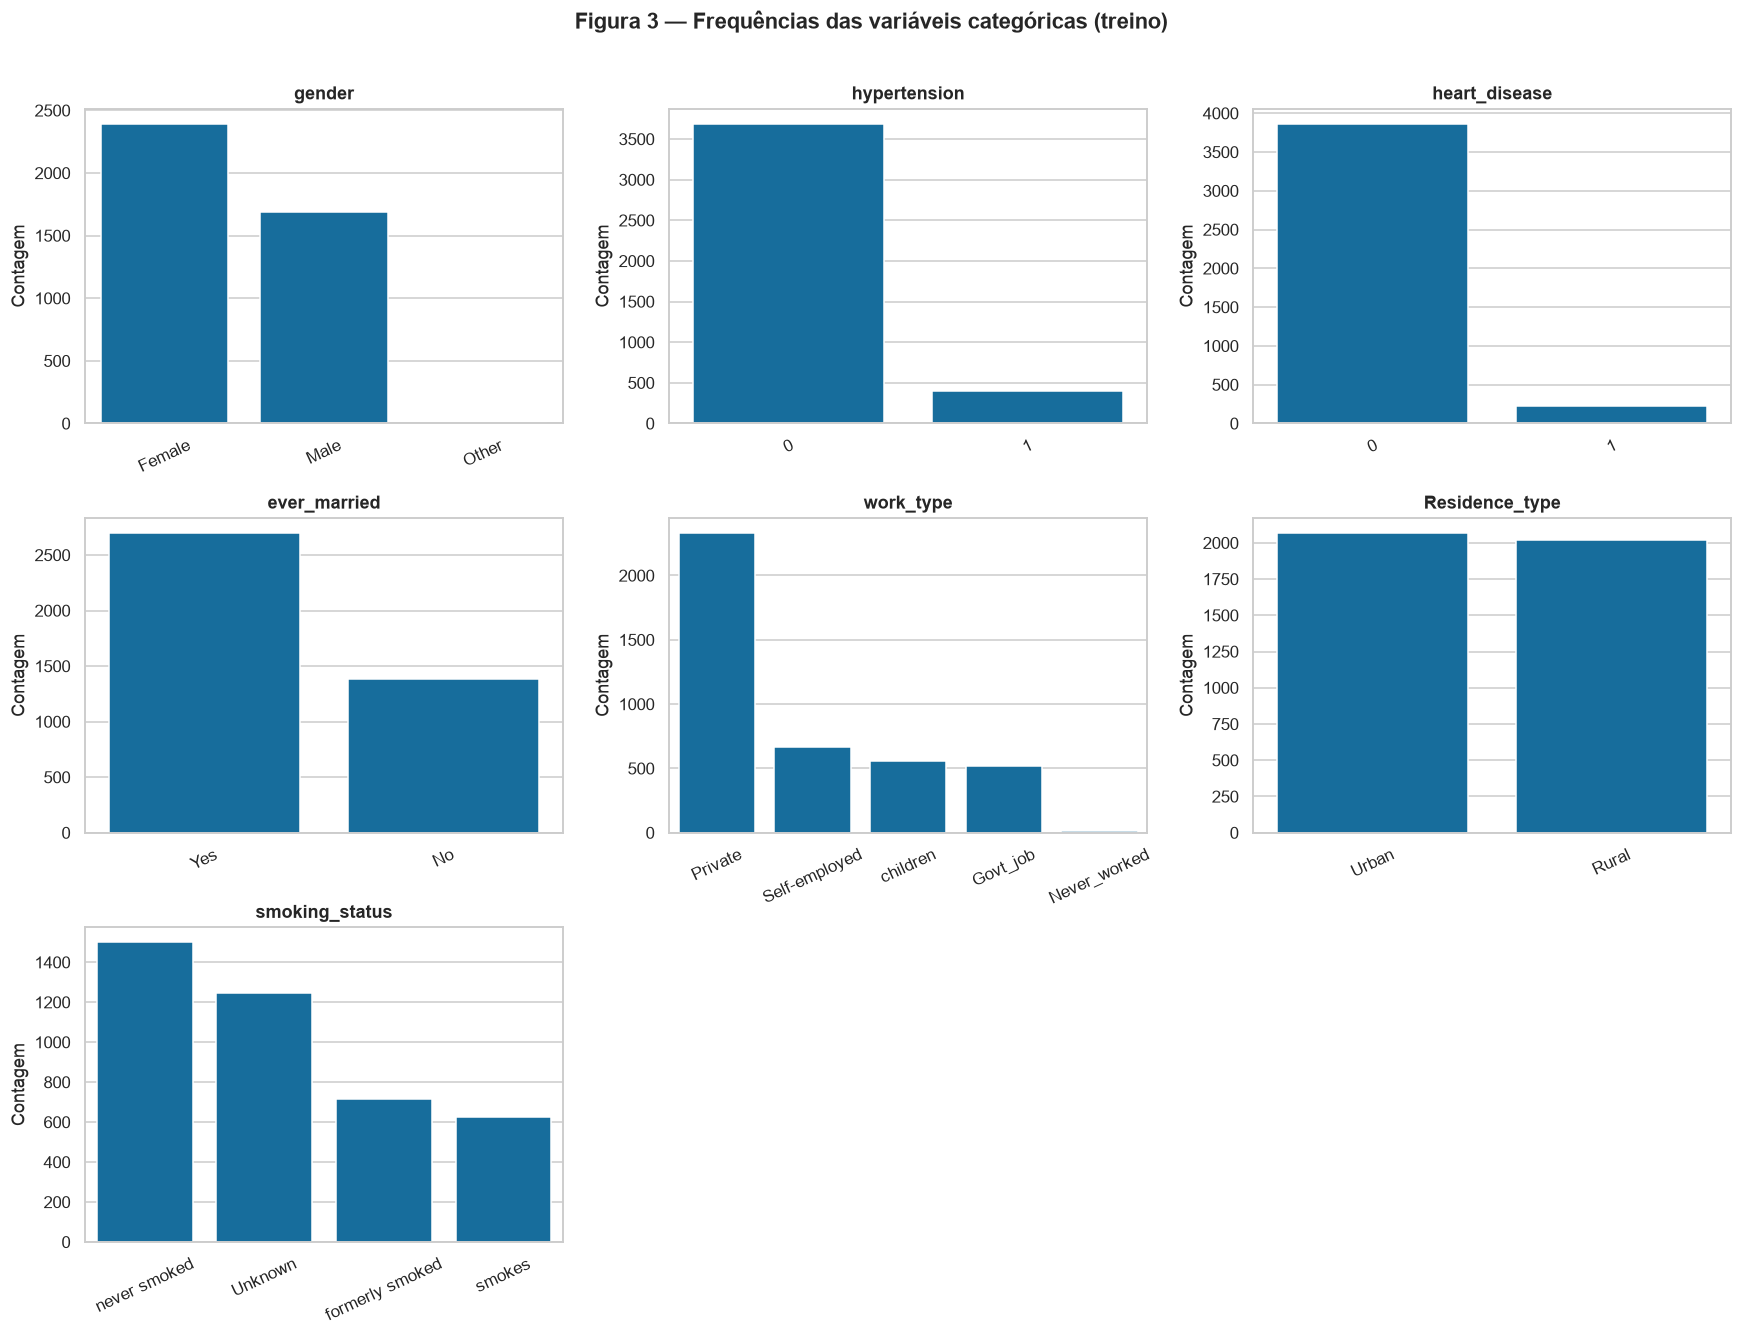


**Conclusão da Figura 3.** Nenhuma variável tem alta cardinalidade: a maior é `work_type`, com **5 categorias**. As categorias abaixo de 1% são **gender=Other (1; 0.02%), work_type=Never_worked (13; 0.32%)**. `Unknown` em tabagismo é frequente e representa informação não coletada; mantê-la separada evita inventar um hábito. One-hot encoding é adequado à baixa cardinalidade, com tolerância explícita a categorias futuras.


In [9]:
fig, axes = plt.subplots(3, 3, figsize=(16, 12))
axes = axes.ravel()
for ax, col in zip(axes, CATEGORICAL_FEATURES):
    order = X_train[col].value_counts().index
    sns.countplot(data=X_train, x=col, order=order, ax=ax)
    ax.set(title=col, xlabel="", ylabel="Contagem")
    ax.tick_params(axis="x", rotation=25)
for ax in axes[len(CATEGORICAL_FEATURES):]:
    ax.remove()
fig.suptitle("Figura 3 — Frequências das variáveis categóricas (treino)", y=1.01, fontweight="bold")
plt.tight_layout()
plt.show()

rare = category_frequencies.query("`rara_<1%`")
rare_text = ", ".join(f"{r.variável}={r.categoria} ({r.n}; {r['%']:.2f}%)" for _, r in rare.iterrows())
max_cardinality_col = category_cardinality.index[0]
display(Markdown(f'''
**Conclusão da Figura 3.** Nenhuma variável tem alta cardinalidade: a maior é `{max_cardinality_col}`, com **{int(category_cardinality.iloc[0]['cardinalidade'])} categorias**. As categorias abaixo de 1% são **{rare_text}**. `Unknown` em tabagismo é frequente e representa informação não coletada; mantê-la separada evita inventar um hábito. One-hot encoding é adequado à baixa cardinalidade, com tolerância explícita a categorias futuras.
'''))

## 3. Análises bivariada e multivariada — somente treino

### 3A. Numérica × numérica

Adotamos **Spearman**: glicose e IMC têm assimetria e extremos, e a pergunta exploratória é sobre associação monotônica, não apenas linear. A matriz inclui somente as três medidas contínuas; códigos 0/1 são categorias, não grandezas.

**Tabela 7 — Correlação de Spearman entre variáveis numéricas.**

,age,avg_glucose_level,bmi
age,1.000,0.141,0.381
avg_glucose_level,0.141,1.000,0.113
bmi,0.381,0.113,1.000


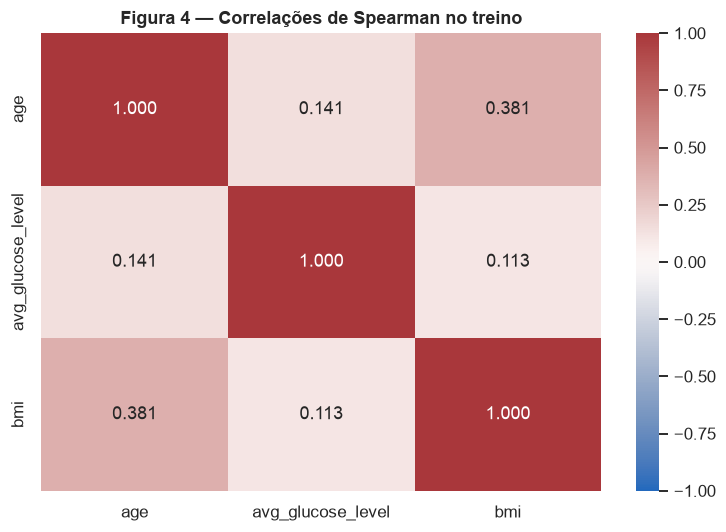


**Conclusão da Figura 4.** O par mais associado é `age` × `bmi`, com **ρ=0.381**. Não há par com **|ρ|≥0,80**, logo nenhuma variável numérica é redundante por esse critério. A associação moderada entre idade e IMC justifica observar a forma da relação, mas não remover uma delas.


In [10]:
spearman_corr = X_train[NUMERIC_FEATURES].corr(method="spearman")
display(Markdown("**Tabela 7 — Correlação de Spearman entre variáveis numéricas.**"))
display(spearman_corr.style.format("{:.3f}"))

fig, ax = plt.subplots(figsize=(7, 5))
sns.heatmap(spearman_corr, annot=True, fmt=".3f", cmap="vlag", center=0, vmin=-1, vmax=1, ax=ax)
ax.set_title("Figura 4 — Correlações de Spearman no treino")
plt.tight_layout()
plt.show()

corr_pairs = spearman_corr.where(np.triu(np.ones(spearman_corr.shape), k=1).astype(bool)).stack()
strongest_pair = corr_pairs.abs().idxmax()
strongest_corr = spearman_corr.loc[strongest_pair[0], strongest_pair[1]]
redundant = corr_pairs[corr_pairs.abs() >= .80]
display(Markdown(f'''
**Conclusão da Figura 4.** O par mais associado é `{strongest_pair[0]}` × `{strongest_pair[1]}`, com **ρ={strongest_corr:.3f}**. Não há par com **|ρ|≥0,80**, logo nenhuma variável numérica é redundante por esse critério. A associação moderada entre idade e IMC justifica observar a forma da relação, mas não remover uma delas.
'''))

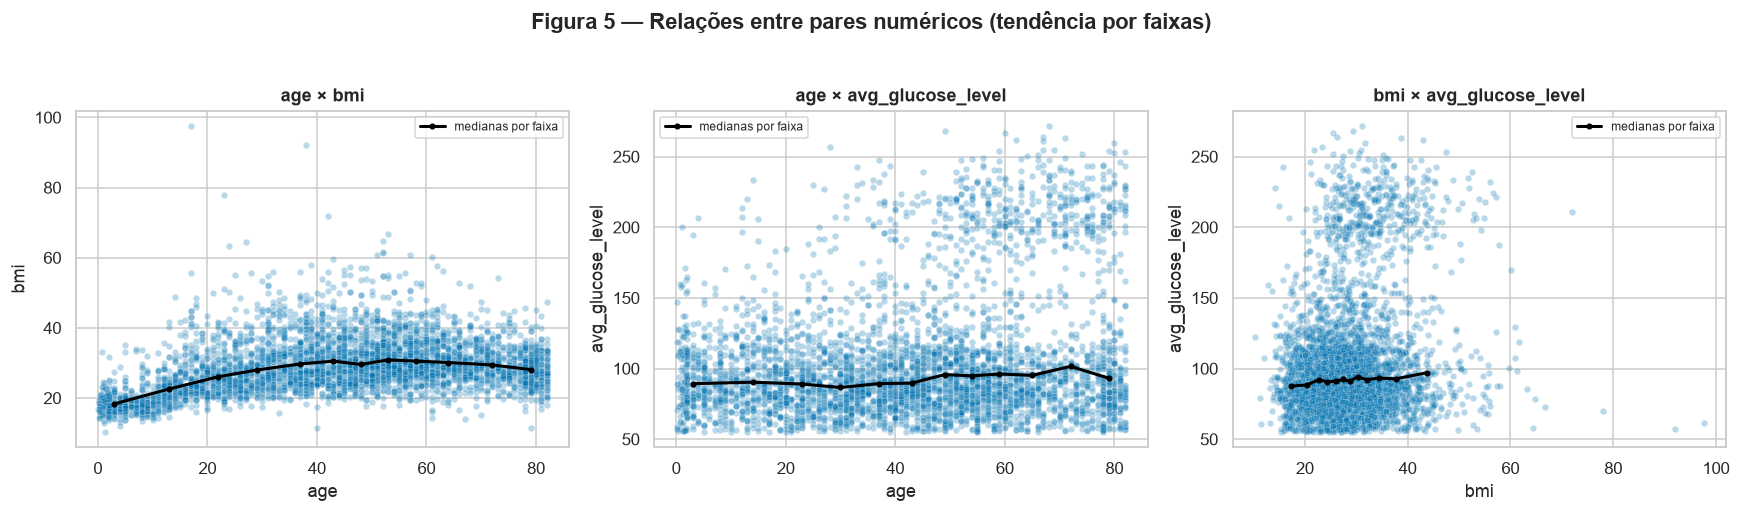


**Conclusão da Figura 5.** A relação idade–IMC cresce sobretudo da infância até a vida adulta e depois se estabiliza, confirmando que não é puramente linear. Glicose apresenta grande dispersão em todas as idades e níveis de IMC. Não há uma dupla quase determinística nem estrutura que justifique excluir uma medida como duplicata.


In [11]:
pairs = [("age", "bmi"), ("age", "avg_glucose_level"), ("bmi", "avg_glucose_level")]
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for ax, (x_col, y_col) in zip(axes, pairs):
    sns.scatterplot(data=X_train, x=x_col, y=y_col, alpha=.28, s=18, ax=ax)
    pair_data = X_train[[x_col, y_col]].dropna().copy()
    pair_data["x_bin"] = pd.qcut(pair_data[x_col], q=12, duplicates="drop")
    trend = pair_data.groupby("x_bin", observed=True)[[x_col, y_col]].median()
    ax.plot(trend[x_col], trend[y_col], color="black", lw=2, marker="o", ms=3,
            label="medianas por faixa")
    ax.legend(fontsize=8)
    ax.set(title=f"{x_col} × {y_col}", xlabel=x_col, ylabel=y_col)
fig.suptitle("Figura 5 — Relações entre pares numéricos (tendência por faixas)", y=1.03, fontweight="bold")
plt.tight_layout()
plt.show()

display(Markdown('''
**Conclusão da Figura 5.** A relação idade–IMC cresce sobretudo da infância até a vida adulta e depois se estabiliza, confirmando que não é puramente linear. Glicose apresenta grande dispersão em todas as idades e níveis de IMC. Não há uma dupla quase determinística nem estrutura que justifique excluir uma medida como duplicata.
'''))

### 3B. Categórica × alvo

In [12]:
train_analysis = X_train.copy()
train_analysis[TARGET] = y_train

cat_target_rows = []
for col in CATEGORICAL_FEATURES:
    grouped = train_analysis.groupby(col, dropna=False)[TARGET].agg(["size", "sum", "mean"]).reset_index()
    grouped["taxa_stroke_%"] = 100 * grouped["mean"]
    grouped.insert(0, "variável", col)
    grouped = grouped.rename(columns={col: "categoria", "size": "n", "sum": "positivos"})
    cat_target_rows.append(grouped[["variável", "categoria", "n", "positivos", "taxa_stroke_%"]])
cat_target = pd.concat(cat_target_rows, ignore_index=True)

display(Markdown("**Tabela 8 — Proporção da classe positiva em cada categoria do treino.**"))
display(cat_target.style.format({"taxa_stroke_%": "{:.2f}%"}))

**Tabela 8 — Proporção da classe positiva em cada categoria do treino.**

,variável,categoria,n,positivos,taxa_stroke_%
0,gender,Female,2395,112,4.68%
1,gender,Male,1692,87,5.14%
2,gender,Other,1,0,0.00%
3,hypertension,0,3691,145,3.93%
4,hypertension,1,397,54,13.60%
5,heart_disease,0,3867,163,4.22%
6,heart_disease,1,221,36,16.29%
7,ever_married,No,1388,23,1.66%
8,ever_married,Yes,2700,176,6.52%
9,work_type,Govt_job,522,28,5.36%


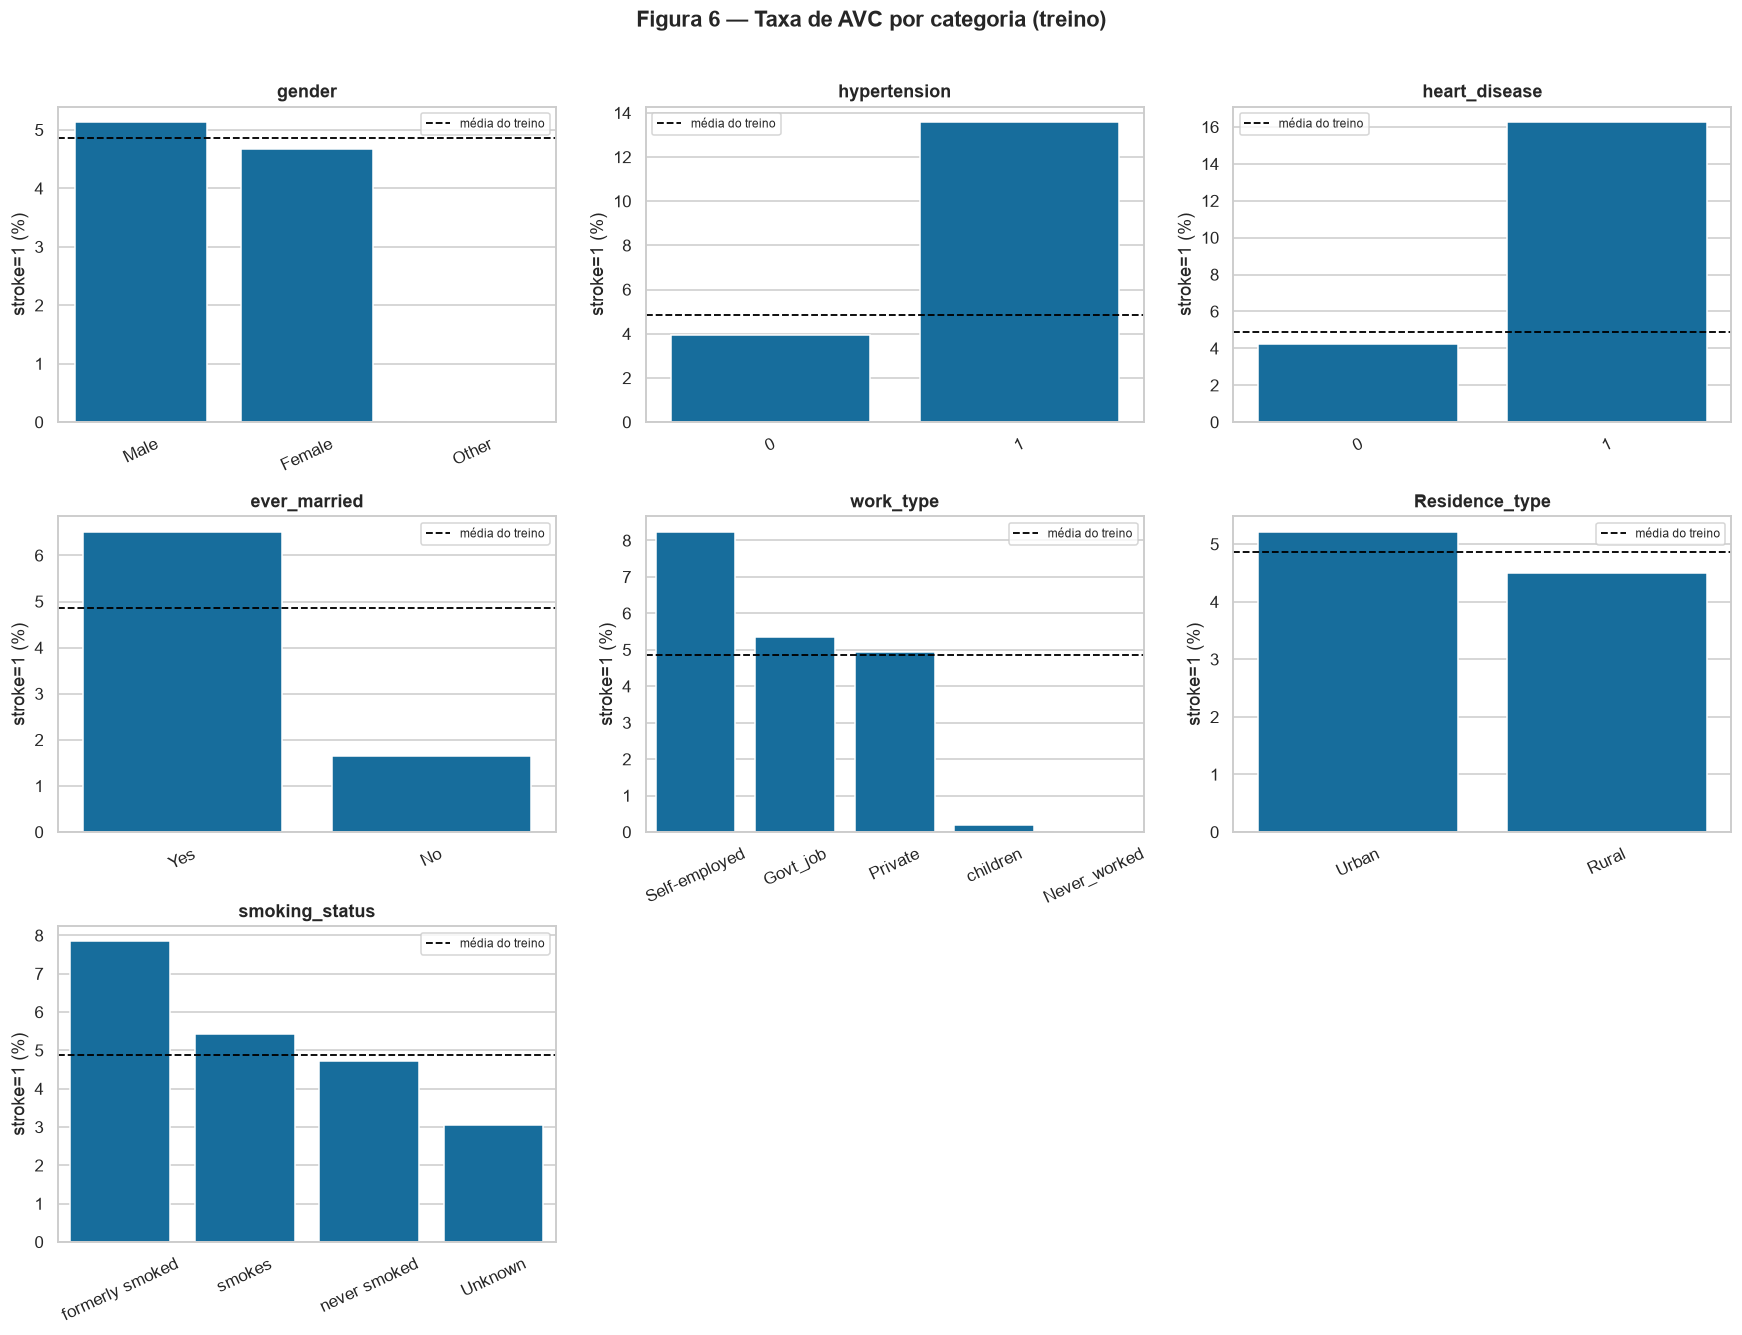


**Conclusão da Figura 6.** `heart_disease` apresenta a maior amplitude bruta entre categorias (**12.07 pontos percentuais**), seguida por `hypertension` (**9.67 p.p.**). As barras de categorias muito pequenas — especialmente `gender=Other` e `work_type=Never_worked` — são instáveis e não devem ser lidas como efeito causal. As diferenças justificam preservar as categorias, mas idade e comorbidades podem ser confundidores.


In [13]:
fig, axes = plt.subplots(3, 3, figsize=(16, 12))
axes = axes.ravel()
for ax, col in zip(axes, CATEGORICAL_FEATURES):
    plot_data = cat_target[cat_target["variável"] == col].sort_values("taxa_stroke_%", ascending=False)
    sns.barplot(data=plot_data, x="categoria", y="taxa_stroke_%", ax=ax)
    ax.axhline(100*y_train.mean(), color="black", ls="--", lw=1.2, label="média do treino")
    ax.set(title=col, xlabel="", ylabel="stroke=1 (%)")
    ax.tick_params(axis="x", rotation=25)
    ax.legend(fontsize=8)
for ax in axes[len(CATEGORICAL_FEATURES):]:
    ax.remove()
fig.suptitle("Figura 6 — Taxa de AVC por categoria (treino)", y=1.01, fontweight="bold")
plt.tight_layout()
plt.show()

rate_ranges = cat_target.groupby("variável")["taxa_stroke_%"].agg(lambda s: s.max()-s.min()).sort_values(ascending=False)
largest_gap_col = rate_ranges.index[0]
largest_gap = rate_ranges.iloc[0]
display(Markdown(f'''
**Conclusão da Figura 6.** `{largest_gap_col}` apresenta a maior amplitude bruta entre categorias (**{largest_gap:.2f} pontos percentuais**), seguida por `{rate_ranges.index[1]}` (**{rate_ranges.iloc[1]:.2f} p.p.**). As barras de categorias muito pequenas — especialmente `gender=Other` e `work_type=Never_worked` — são instáveis e não devem ser lidas como efeito causal. As diferenças justificam preservar as categorias, mas idade e comorbidades podem ser confundidores.
'''))

### 3C. Numérica × categórica

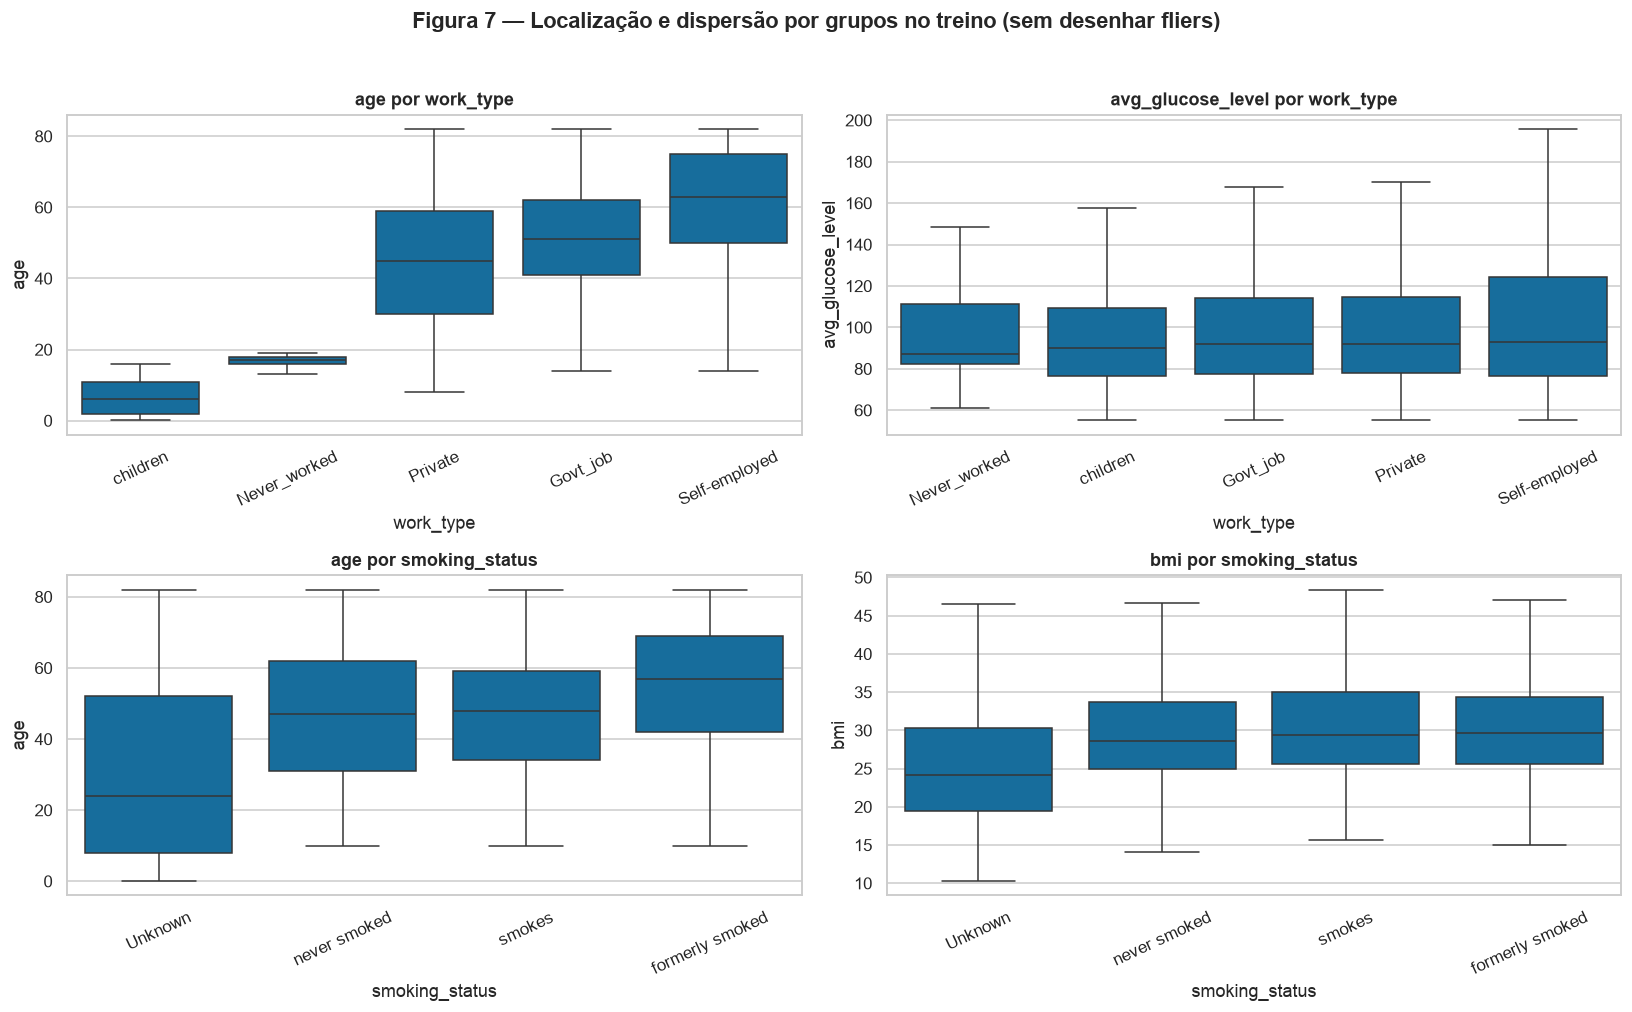


**Conclusão da Figura 7.** Em `work_type`, as medianas de idade vão de **6.0** a **63.0 anos**, e a dispersão também muda entre grupos; a categoria `children` explica parte dessa separação. Em tabagismo, as medianas vão de **24.0** a **57.0 anos**, evidenciando forte associação com idade. Portanto, diferenças categóricas no alvo não podem ser interpretadas isoladamente como efeitos do trabalho ou tabagismo.


In [14]:
fig, axes = plt.subplots(2, 2, figsize=(15, 9))
box_specs = [
    ("work_type", "age"),
    ("work_type", "avg_glucose_level"),
    ("smoking_status", "age"),
    ("smoking_status", "bmi"),
]
for ax, (cat_col, num_col) in zip(axes.ravel(), box_specs):
    order = X_train.groupby(cat_col)[num_col].median().sort_values().index
    sns.boxplot(data=X_train, x=cat_col, y=num_col, order=order, showfliers=False, ax=ax)
    ax.set(title=f"{num_col} por {cat_col}", xlabel=cat_col, ylabel=num_col)
    ax.tick_params(axis="x", rotation=25)
fig.suptitle("Figura 7 — Localização e dispersão por grupos no treino (sem desenhar fliers)", y=1.02, fontweight="bold")
plt.tight_layout()
plt.show()

work_age = X_train.groupby("work_type")["age"].agg(["median", "std"])
smoke_age = X_train.groupby("smoking_status")["age"].agg(["median", "std"])
display(Markdown(f'''
**Conclusão da Figura 7.** Em `work_type`, as medianas de idade vão de **{work_age['median'].min():.1f}** a **{work_age['median'].max():.1f} anos**, e a dispersão também muda entre grupos; a categoria `children` explica parte dessa separação. Em tabagismo, as medianas vão de **{smoke_age['median'].min():.1f}** a **{smoke_age['median'].max():.1f} anos**, evidenciando forte associação com idade. Portanto, diferenças categóricas no alvo não podem ser interpretadas isoladamente como efeitos do trabalho ou tabagismo.
'''))

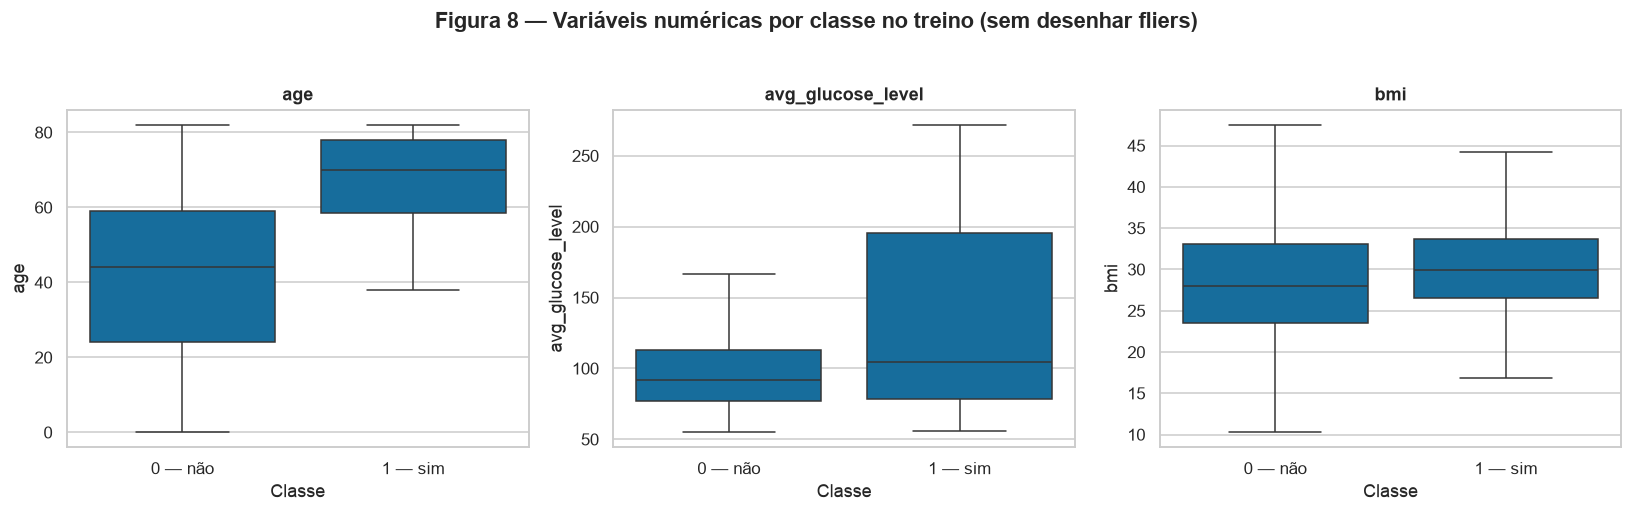

,mediana_stroke_0,mediana_stroke_1,diferença
age,44.00,70.00,26.00
avg_glucose_level,91.65,104.86,13.21
bmi,27.95,29.90,1.95



**Conclusão da Figura 8.** A maior mudança de localização é em idade: a mediana passa de **44.0** para **70.0 anos**. Glicose também se desloca e mantém maior dispersão entre positivos. IMC tem sobreposição substancial. Esses são sinais associativos; não demonstram causalidade e podem refletir composição etária e comorbidades.


In [15]:
plot_target = train_analysis.copy()
plot_target["stroke_label"] = plot_target[TARGET].map({0: "0 — não", 1: "1 — sim"})
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
for ax, col in zip(axes, NUMERIC_FEATURES):
    sns.boxplot(data=plot_target, x="stroke_label", y=col, showfliers=False, ax=ax)
    ax.set(title=col, xlabel="Classe", ylabel=col)
fig.suptitle("Figura 8 — Variáveis numéricas por classe no treino (sem desenhar fliers)", y=1.03, fontweight="bold")
plt.tight_layout()
plt.show()

num_by_target = train_analysis.groupby(TARGET)[NUMERIC_FEATURES].median().T
num_by_target.columns = ["mediana_stroke_0", "mediana_stroke_1"]
num_by_target["diferença"] = num_by_target["mediana_stroke_1"] - num_by_target["mediana_stroke_0"]
display(num_by_target.style.format("{:.2f}"))
display(Markdown(f'''
**Conclusão da Figura 8.** A maior mudança de localização é em idade: a mediana passa de **{num_by_target.loc['age', 'mediana_stroke_0']:.1f}** para **{num_by_target.loc['age', 'mediana_stroke_1']:.1f} anos**. Glicose também se desloca e mantém maior dispersão entre positivos. IMC tem sobreposição substancial. Esses são sinais associativos; não demonstram causalidade e podem refletir composição etária e comorbidades.
'''))

## 4. Pré-processamento

### 4A. Estratégias motivadas pelos achados

| Componente | Estratégia (ajustada somente no treino) | Evidência e motivo |
|---|---|---|
| Ausentes | `SimpleImputer(strategy="median")` em numéricas; moda defensiva em categóricas | `bmi` é a única coluna com ausência (Tabela 2) e tem cauda direita (Figura 2); a mediana é mais robusta que a média. |
| Extremos | `IQRClipper(factor=1.5)` por coluna, depois da imputação | Glicose e IMC têm cauda/extremos (Figura 2). Clipping preserva a classe rara, ao contrário de remover linhas. Limites vêm apenas do treino. |
| Categorias | `OneHotEncoder(handle_unknown="ignore")` | Baixa cardinalidade (Tabela 5) e ausência de ordem natural. O parâmetro suporta categoria inédita no teste. `Unknown` de tabagismo continua explícita. |
| Escala | `StandardScaler` nas três numéricas, depois do clipping | As amplitudes diferem (idade, glicose e IMC) e redes neurais/PCA são sensíveis à escala. One-hot permanece em 0/1. |

Indicadores binários são tratados como categóricos. `id` já foi removido. O objeto é criado pela função importável `code/preprocessing.py`; não há ajuste oculto fora do pipeline.

In [16]:
preprocess = build_preprocessor()
X_train_t = preprocess.fit_transform(X_train)  # único fit
X_test_t = preprocess.transform(X_test)        # nunca fit no teste
feature_names = preprocess.get_feature_names_out()

# Quantifica o impacto do clipping com os limites realmente aprendidos no treino.
num_pipe = preprocess.named_transformers_["num"]
imputer = num_pipe.named_steps["imputer"]
clipper = num_pipe.named_steps["outliers"]
train_num_imputed = imputer.transform(X_train[NUMERIC_FEATURES])
test_num_imputed = imputer.transform(X_test[NUMERIC_FEATURES])
train_clipped_mask = ((train_num_imputed < clipper.lower_bounds_) | (train_num_imputed > clipper.upper_bounds_))
test_clipped_mask = ((test_num_imputed < clipper.lower_bounds_) | (test_num_imputed > clipper.upper_bounds_))
train_rows_clipped = int(train_clipped_mask.any(axis=1).sum())
test_rows_clipped = int(test_clipped_mask.any(axis=1).sum())

bounds = pd.DataFrame({
    "limite_inferior": clipper.lower_bounds_,
    "limite_superior": clipper.upper_bounds_,
    "valores_clipados_treino": train_clipped_mask.sum(axis=0),
}, index=NUMERIC_FEATURES)
display(Markdown("**Tabela 9 — Limites de Tukey aprendidos e impacto no treino.**"))
display(bounds.style.format({"limite_inferior": "{:.2f}", "limite_superior": "{:.2f}"}))
display(Markdown(f'''
O clipping afeta **{train_rows_clipped:,}/{len(X_train):,} linhas de treino ({100*train_rows_clipped/len(X_train):.2f}%)** e **{test_rows_clipped:,}/{len(X_test):,} linhas de teste ({100*test_rows_clipped/len(X_test):.2f}%)**. Nenhuma linha é removida.
'''))

**Tabela 9 — Limites de Tukey aprendidos e impacto no treino.**

,limite_inferior,limite_superior,valores_clipados_treino
age,-26.50,113.50,0
avg_glucose_level,21.98,169.53,503
bmi,10.30,46.30,101



O clipping afeta **577/4,088 linhas de treino (14.11%)** e **140/1,022 linhas de teste (13.70%)**. Nenhuma linha é removida.


In [17]:
# Teste explícito de categoria que não existia durante o fit.
novel = X_test.iloc[[0]].copy()
novel["work_type"] = "categoria_inedita"
novel_t = preprocess.transform(novel)

assert X_train_t.shape[0] == len(X_train)
assert X_test_t.shape[0] == len(X_test)
assert not np.isnan(X_train_t).any() and not np.isnan(X_test_t).any()
assert np.isfinite(X_train_t).all() and np.isfinite(X_test_t).all()
assert novel_t.shape[1] == X_train_t.shape[1]

print("Categoria inédita transformada sem erro:", novel_t.shape)

Categoria inédita transformada sem erro: (1, 23)


### 4B. Redução de dimensionalidade

As projeções usam as variáveis **já transformadas pelo pipeline ajustado no treino**. PCA é ajustada em todo o treino. Para custo e comparação justa, t-SNE e UMAP usam a mesma amostra estratificada de até 2.000 linhas; as projeções são visualizações exploratórias, nunca entrada para conclusões clínicas. Distâncias globais e tamanhos aparentes de clusters em t-SNE/UMAP não têm leitura direta.

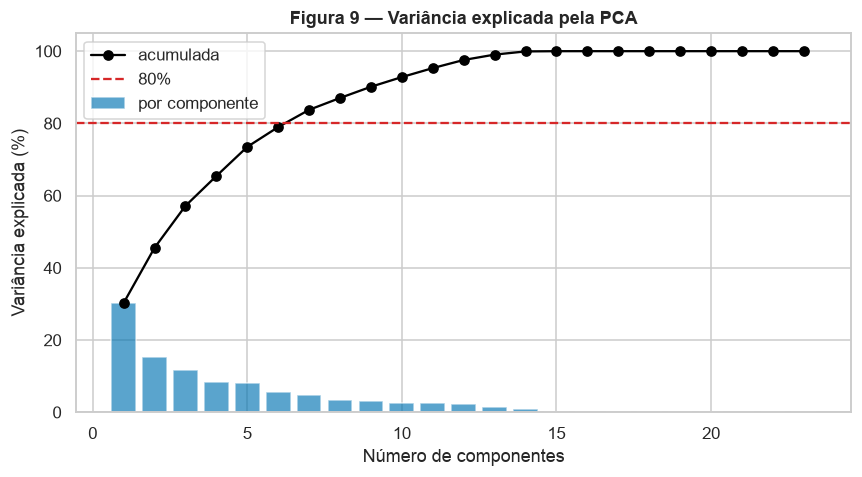


**Conclusão da Figura 9.** PC1+PC2 explicam **45.53%** da variância transformada; são necessários **7 componentes** para atingir ao menos 80%. Logo, o plano 2D perde informação relevante e serve para visualização, não como substituto automático das variáveis no modelo.


In [18]:
pca = PCA(random_state=SEED)
X_train_pca_all = pca.fit_transform(X_train_t)
cum_var = np.cumsum(pca.explained_variance_ratio_)

fig, ax = plt.subplots(figsize=(8, 4.5))
components = np.arange(1, len(cum_var) + 1)
ax.bar(components, 100*pca.explained_variance_ratio_, alpha=.65, label="por componente")
ax.plot(components, 100*cum_var, marker="o", color="black", label="acumulada")
ax.axhline(80, color="tab:red", ls="--", label="80%")
ax.set(title="Figura 9 — Variância explicada pela PCA", xlabel="Número de componentes", ylabel="Variância explicada (%)")
ax.legend()
plt.tight_layout()
plt.show()

pc12_variance = 100 * cum_var[1]
n_components_80 = int(np.argmax(cum_var >= .80) + 1)
display(Markdown(f'''
**Conclusão da Figura 9.** PC1+PC2 explicam **{pc12_variance:.2f}%** da variância transformada; são necessários **{n_components_80} componentes** para atingir ao menos 80%. Logo, o plano 2D perde informação relevante e serve para visualização, não como substituto automático das variáveis no modelo.
'''))

**Tabela 10 — Seis maiores loadings absolutos em PC1 e PC2.**

,componente,feature,loading,|loading|
0,PC1,num__age,0.632,0.632
1,PC1,num__bmi,0.528,0.528
2,PC1,num__avg_glucose_level,0.310,0.310
3,PC1,cat__ever_married_No,-0.259,0.259
4,PC1,cat__ever_married_Yes,0.259,0.259
5,PC1,cat__work_type_children,-0.180,0.180
6,PC2,num__avg_glucose_level,0.939,0.939
7,PC2,num__bmi,-0.202,0.202
8,PC2,num__age,-0.157,0.157
9,PC2,cat__ever_married_Yes,-0.093,0.093


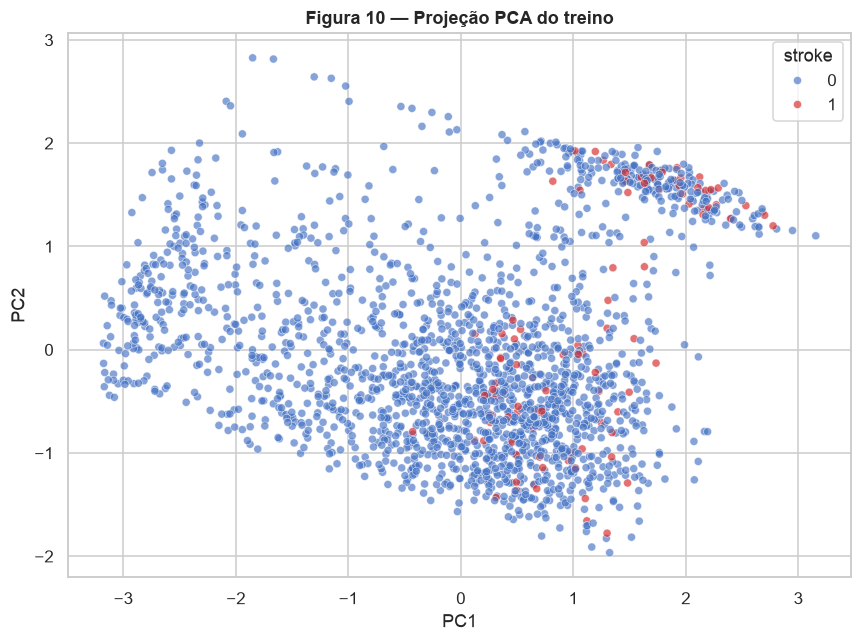


**Conclusão da Figura 10.** As classes se sobrepõem amplamente no plano linear. Os maiores pesos absolutos são `num__age` em PC1 (**0.632**) e `num__avg_glucose_level` em PC2 (**0.939**); sinais indicam direção, e categorias one-hot da mesma variável devem ser lidas em conjunto. Não aparece fronteira linear simples entre as classes.


In [19]:
loadings = pd.DataFrame(
    pca.components_[:2].T,
    index=feature_names,
    columns=["PC1", "PC2"],
)
top_loadings = pd.concat([
    loadings["PC1"].abs().nlargest(6).rename("|loading|").to_frame().assign(componente="PC1", loading=loadings["PC1"]),
    loadings["PC2"].abs().nlargest(6).rename("|loading|").to_frame().assign(componente="PC2", loading=loadings["PC2"]),
]).reset_index(names="feature")
display(Markdown("**Tabela 10 — Seis maiores loadings absolutos em PC1 e PC2.**"))
display(top_loadings[["componente", "feature", "loading", "|loading|"]].style.format({"loading": "{:.3f}", "|loading|": "{:.3f}"}))

sample_n = min(2000, len(X_train))
sample_index, _ = train_test_split(
    np.arange(len(X_train)), train_size=sample_n, random_state=SEED, stratify=y_train.to_numpy()
)
X_vis = X_train_t[sample_index]
y_vis = y_train.to_numpy()[sample_index]
X_pca_2d = pca.transform(X_vis)[:, :2]

fig, ax = plt.subplots(figsize=(8, 6))
sns.scatterplot(x=X_pca_2d[:, 0], y=X_pca_2d[:, 1], hue=y_vis, palette={0: "#4472C4", 1: "#D62728"},
                alpha=.65, s=28, ax=ax)
ax.set(title="Figura 10 — Projeção PCA do treino", xlabel="PC1", ylabel="PC2")
ax.legend(title="stroke")
plt.tight_layout()
plt.show()

pc1_top = top_loadings.query("componente == 'PC1'").iloc[0]
pc2_top = top_loadings.query("componente == 'PC2'").iloc[0]
display(Markdown(f'''
**Conclusão da Figura 10.** As classes se sobrepõem amplamente no plano linear. Os maiores pesos absolutos são `{pc1_top.feature}` em PC1 (**{pc1_top.loading:.3f}**) e `{pc2_top.feature}` em PC2 (**{pc2_top.loading:.3f}**); sinais indicam direção, e categorias one-hot da mesma variável devem ser lidas em conjunto. Não aparece fronteira linear simples entre as classes.
'''))

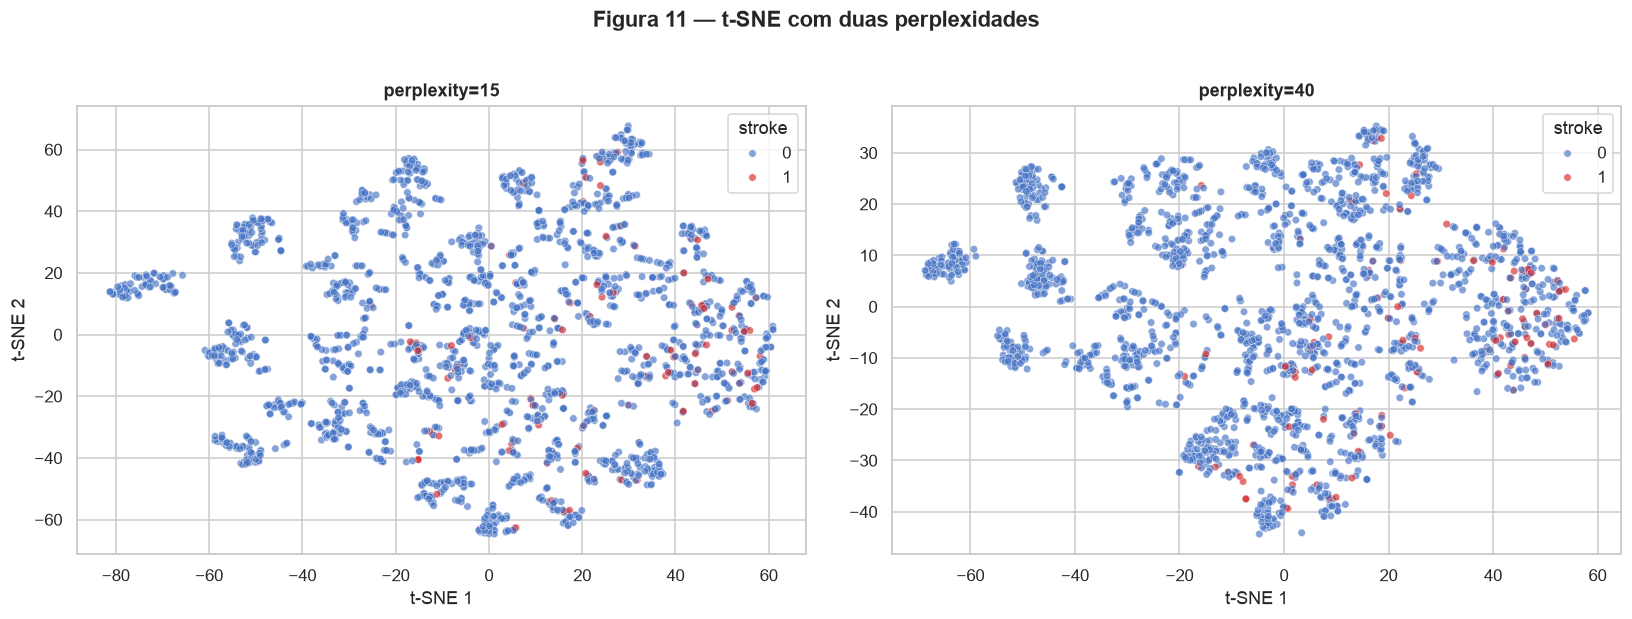


**Conclusão da Figura 11.** A geometria local muda com a perplexidade, mas em ambas as configurações os positivos permanecem misturados à classe majoritária; não surge um agrupamento robusto exclusivo de AVC. Formas, áreas, distâncias entre ilhas e tamanhos aparentes não representam prevalência ou distância original.


In [20]:
tsne_iter_kw = {"max_iter": 1000} if "max_iter" in inspect.signature(TSNE).parameters else {"n_iter": 1000}
tsne_embeddings = {}
for perplexity in (15, 40):
    tsne_embeddings[perplexity] = TSNE(
        n_components=2,
        perplexity=perplexity,
        init="pca",
        learning_rate="auto",
        random_state=SEED,
        **tsne_iter_kw,
    ).fit_transform(X_vis)

fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))
for ax, (perplexity, embedding) in zip(axes, tsne_embeddings.items()):
    sns.scatterplot(x=embedding[:, 0], y=embedding[:, 1], hue=y_vis,
                    palette={0: "#4472C4", 1: "#D62728"}, alpha=.65, s=24, ax=ax)
    ax.set(title=f"perplexity={perplexity}", xlabel="t-SNE 1", ylabel="t-SNE 2")
    ax.legend(title="stroke")
fig.suptitle("Figura 11 — t-SNE com duas perplexidades", y=1.02, fontweight="bold")
plt.tight_layout()
plt.show()

display(Markdown('''
**Conclusão da Figura 11.** A geometria local muda com a perplexidade, mas em ambas as configurações os positivos permanecem misturados à classe majoritária; não surge um agrupamento robusto exclusivo de AVC. Formas, áreas, distâncias entre ilhas e tamanhos aparentes não representam prevalência ou distância original.
'''))

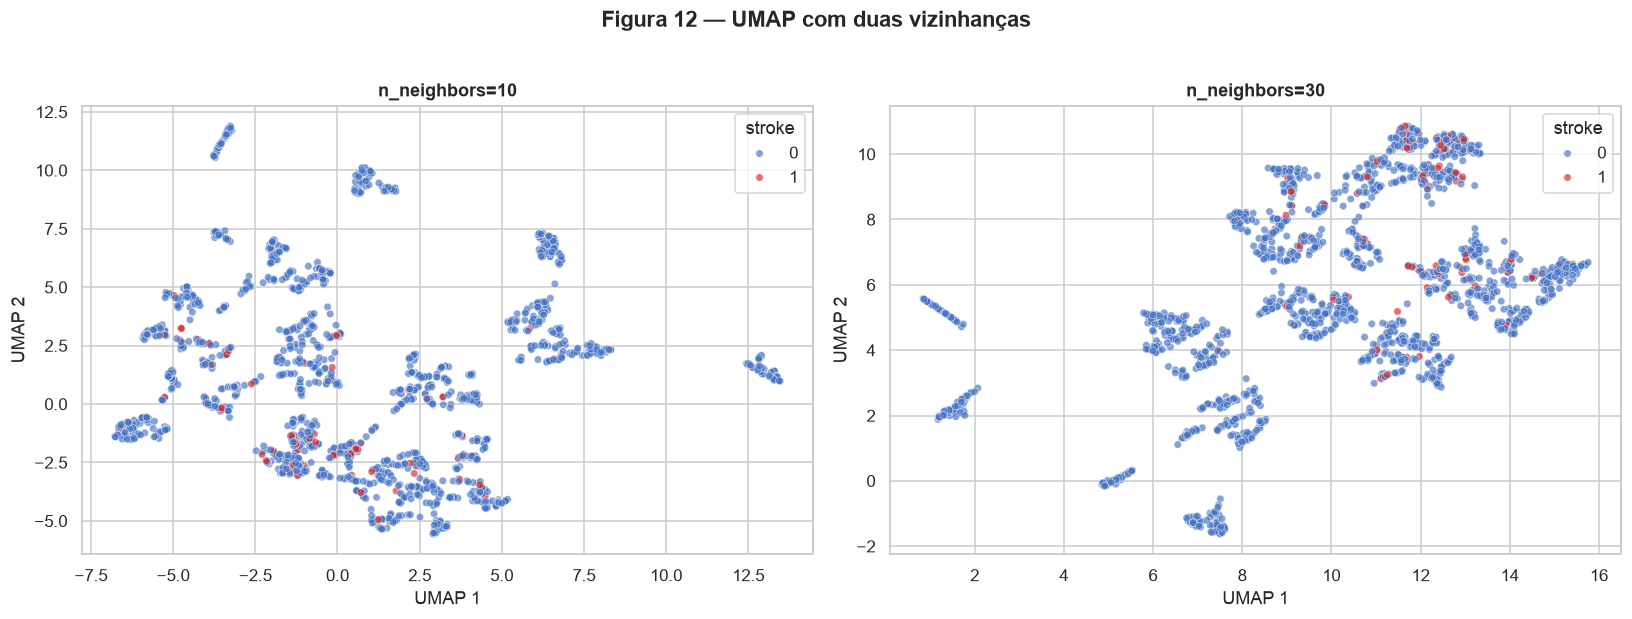


**Conclusão da Figura 12.** UMAP evidencia subestruturas locais mais nítidas que PCA, sensíveis ao número de vizinhos, porém os positivos continuam distribuídos entre regiões dominadas por negativos. As ilhas podem refletir combinações de categorias one-hot; não são subtipos clínicos comprovados, e distância/área entre elas não tem interpretação direta.


In [21]:
umap_embeddings = {}
for n_neighbors in (10, 30):
    umap_embeddings[n_neighbors] = umap.UMAP(
        n_components=2,
        n_neighbors=n_neighbors,
        min_dist=.10,
        metric="euclidean",
        random_state=SEED,
        n_jobs=1,
    ).fit_transform(X_vis)

fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))
for ax, (n_neighbors, embedding) in zip(axes, umap_embeddings.items()):
    sns.scatterplot(x=embedding[:, 0], y=embedding[:, 1], hue=y_vis,
                    palette={0: "#4472C4", 1: "#D62728"}, alpha=.65, s=24, ax=ax)
    ax.set(title=f"n_neighbors={n_neighbors}", xlabel="UMAP 1", ylabel="UMAP 2")
    ax.legend(title="stroke")
fig.suptitle("Figura 12 — UMAP com duas vizinhanças", y=1.02, fontweight="bold")
plt.tight_layout()
plt.show()

display(Markdown('''
**Conclusão da Figura 12.** UMAP evidencia subestruturas locais mais nítidas que PCA, sensíveis ao número de vizinhos, porém os positivos continuam distribuídos entre regiões dominadas por negativos. As ilhas podem refletir combinações de categorias one-hot; não são subtipos clínicos comprovados, e distância/área entre elas não tem interpretação direta.
'''))

In [22]:
projection_rows = [{
    "método": "PCA (2D)",
    "parâmetro": "2 componentes",
    "trustworthiness_k=10": trustworthiness(X_vis, X_pca_2d, n_neighbors=10),
    "silhouette_do_alvo": silhouette_score(X_pca_2d, y_vis),
}]
for perplexity, emb in tsne_embeddings.items():
    projection_rows.append({
        "método": "t-SNE", "parâmetro": f"perplexity={perplexity}",
        "trustworthiness_k=10": trustworthiness(X_vis, emb, n_neighbors=10),
        "silhouette_do_alvo": silhouette_score(emb, y_vis),
    })
for n_neighbors, emb in umap_embeddings.items():
    projection_rows.append({
        "método": "UMAP", "parâmetro": f"n_neighbors={n_neighbors}",
        "trustworthiness_k=10": trustworthiness(X_vis, emb, n_neighbors=10),
        "silhouette_do_alvo": silhouette_score(emb, y_vis),
    })
projection_metrics = pd.DataFrame(projection_rows)
display(Markdown("**Tabela 11 — Diagnóstico quantitativo das projeções (mesma amostra).**"))
display(projection_metrics.style.format({"trustworthiness_k=10": "{:.3f}", "silhouette_do_alvo": "{:.3f}"}))

best_trust = projection_metrics.loc[projection_metrics["trustworthiness_k=10"].idxmax()]
display(Markdown(f'''
**Comparação.** PCA preserva uma leitura linear e loadings, mas comprime muita variância fora do plano. t-SNE e UMAP preservam melhor algumas vizinhanças e mostram subestruturas que PCA não separa; a maior trustworthiness foi **{best_trust['trustworthiness_k=10']:.3f}** em **{best_trust['método']} ({best_trust['parâmetro']})**. O silhouette calculado apenas com os rótulos é diagnóstico, não avaliação de modelo: valores próximos de zero confirmam sobreposição. Nenhuma projeção autoriza interpretar clusters, suas distâncias ou seus tamanhos como grupos clínicos reais.
'''))

**Tabela 11 — Diagnóstico quantitativo das projeções (mesma amostra).**

,método,parâmetro,trustworthiness_k=10,silhouette_do_alvo
0,PCA (2D),2 componentes,0.822,0.016
1,t-SNE,perplexity=15,0.989,-0.030
2,t-SNE,perplexity=40,0.988,0.006
3,UMAP,n_neighbors=10,0.982,-0.125
4,UMAP,n_neighbors=30,0.977,-0.085



**Comparação.** PCA preserva uma leitura linear e loadings, mas comprime muita variância fora do plano. t-SNE e UMAP preservam melhor algumas vizinhanças e mostram subestruturas que PCA não separa; a maior trustworthiness foi **0.989** em **t-SNE (perplexity=15)**. O silhouette calculado apenas com os rótulos é diagnóstico, não avaliação de modelo: valores próximos de zero confirmam sobreposição. Nenhuma projeção autoriza interpretar clusters, suas distâncias ou seus tamanhos como grupos clínicos reais.


### 4C. Pipeline final e verificações

In [23]:
feature_table = pd.DataFrame({"posição": np.arange(len(feature_names)), "feature": feature_names})
display(Markdown("**Tabela 12 — Nomes das features produzidas pelo pipeline.**"))
display(feature_table)

pipeline_checks = pd.DataFrame({
    "partição": ["treino", "teste"],
    "shape": [str(X_train_t.shape), str(X_test_t.shape)],
    "NaN": [int(np.isnan(X_train_t).sum()), int(np.isnan(X_test_t).sum())],
    "não_finitos": [int((~np.isfinite(X_train_t)).sum()), int((~np.isfinite(X_test_t)).sum())],
})
display(Markdown("**Tabela 13 — Auditoria da saída do pipeline.**"))
display(pipeline_checks)

display(Markdown(f'''
O `ColumnTransformer` foi **ajustado uma única vez em {len(X_train):,} linhas de treino**. As saídas têm `shape` **{X_train_t.shape} no treino** e **{X_test_t.shape} no teste**, com **0 `NaN` e 0 valores não finitos**. Foram geradas **{len(feature_names)} features nomeadas**. A transformação da categoria artificial inédita foi bem-sucedida, mantendo o mesmo número de colunas. A implementação reutilizável está em `code/preprocessing.py`.
'''))

**Tabela 12 — Nomes das features produzidas pelo pipeline.**

,posição,feature
0,0,num__age
1,1,num__avg_glucose_level
2,2,num__bmi
3,3,cat__gender_Female
4,4,cat__gender_Male
5,5,cat__gender_Other
6,6,cat__hypertension_0
7,7,cat__hypertension_1
8,8,cat__heart_disease_0
9,9,cat__heart_disease_1


**Tabela 13 — Auditoria da saída do pipeline.**

,partição,shape,NaN,não_finitos
0,treino,"(4088, 23)",0,0
1,teste,"(1022, 23)",0,0



O `ColumnTransformer` foi **ajustado uma única vez em 4,088 linhas de treino**. As saídas têm `shape` **(4088, 23) no treino** e **(1022, 23) no teste**, com **0 `NaN` e 0 valores não finitos**. Foram geradas **23 features nomeadas**. A transformação da categoria artificial inédita foi bem-sucedida, mantendo o mesmo número de colunas. A implementação reutilizável está em `code/preprocessing.py`.


## 5. Síntese para a etapa de modelagem

In [24]:
positive_train = train_analysis.loc[train_analysis[TARGET] == 1]
summary = pd.DataFrame([
    (1, "Dataset, tarefa e alvo", "Stroke Prediction; classificação binária; stroke"),
    (2, "Instâncias × preditoras (numéricas / categóricas)", f"{len(df):,} × {X.shape[1]} ({len(NUMERIC_FEATURES)} / {len(CATEGORICAL_FEATURES)}); bruto: {df.shape[0]:,} × {df.shape[1]}"),
    (3, "Coluna com mais ausentes", f"bmi: {int(missing.loc['bmi','ausentes_n'])} ({missing.loc['bmi','ausentes_%']:.2f}%)"),
    (4, "Colunas descartadas e motivo", "id — identificador único, sem significado preditivo"),
    (5, "Classe minoritária", f"stroke=1: {int((df[TARGET]==1).sum())} ({100*df[TARGET].mean():.2f}%)"),
    (6, "Tamanho treino / teste", f"{len(X_train):,} / {len(X_test):,}"),
    (7, "Par numérico mais correlacionado", f"{strongest_pair[0]} × {strongest_pair[1]}: Spearman ρ={strongest_corr:.3f}"),
    (8, "Linhas afetadas pelo clipping", f"treino: {train_rows_clipped:,} ({100*train_rows_clipped/len(X_train):.2f}%); teste: {test_rows_clipped:,} ({100*test_rows_clipped/len(X_test):.2f}%)"),
    (9, "Variância explicada por PC1+PC2", f"{pc12_variance:.2f}%"),
    (10, "Shapes após o pipeline", f"treino {X_train_t.shape}; teste {X_test_t.shape}"),
], columns=["#", "Resultado", "Valor"])
display(Markdown("**Tabela 14 — Índice final dos resultados.**"))
display(summary.style.hide(axis="index"))

**Tabela 14 — Índice final dos resultados.**

#,Resultado,Valor
1,"Dataset, tarefa e alvo",Stroke Prediction; classificação binária; stroke
2,Instâncias × preditoras (numéricas / categóricas),"5,110 × 10 (3 / 7); bruto: 5,110 × 12"
3,Coluna com mais ausentes,bmi: 201 (3.93%)
4,Colunas descartadas e motivo,"id — identificador único, sem significado preditivo"
5,Classe minoritária,stroke=1: 249 (4.87%)
6,Tamanho treino / teste,"4,088 / 1,022"
7,Par numérico mais correlacionado,age × bmi: Spearman ρ=0.381
8,Linhas afetadas pelo clipping,treino: 577 (14.11%); teste: 140 (13.70%)
9,Variância explicada por PC1+PC2,45.53%
10,Shapes após o pipeline,"treino (4088, 23); teste (1022, 23)"


### Principais achados e implicações

1. **O desafio dominante é o desbalanceamento**: somente 4,87% são positivos (Tabela 3/Figura 1). O próximo entregável deve usar métricas adequadas, split estratificado e pesos de classe ou reamostragem **apenas dentro do treino**; o teste não deve ser rebalanceado.
2. **Idade é o sinal exploratório mais evidente**: muda fortemente entre classes (Figura 8) e também estrutura trabalho e tabagismo (Figura 7). Relações categóricas não devem ser interpretadas causalmente sem controlar esses confundidores.
3. **Glicose e IMC têm caudas/extremos** (Figura 2). O clipping por IQR limita influência sem descartar positivos raros; o número de linhas afetadas está na Tabela 14. Na modelagem, comparar por validação com uma versão sem clipping é uma análise de sensibilidade recomendada.
4. **Não há redundância numérica forte** (Tabela 7/Figuras 4–5), então as três medidas contínuas são mantidas.
5. **PCA, t-SNE e UMAP não separam claramente o alvo** (Figuras 10–12 e Tabela 11). Uma rede neural poderá explorar interações, mas as projeções não sustentam expectativa de separação fácil.

### Riscos e plano de tratamento

- **Validade externa e justiça:** fonte original, país, período e amostragem não são informados; gênero tem somente uma observação em `Other`. Não usar clinicamente. Reportar métricas por subgrupo quando houver tamanho suficiente e explicitar quando não houver.
- **Informação ausente:** IMC é imputado e tabagismo desconhecido fica explícito. Na etapa de modelos, testar um indicador de ausência de IMC e comparar via validação.
- **Classe rara:** aplicar pesos/reamostragem somente nos folds de treino; selecionar limiar na validação; manter a prevalência natural no teste.
- **Vazamento:** `id` foi removido e todo `fit` ocorreu no treino. Na próxima entrega, colocar pré-processamento e estimador no mesmo `Pipeline` durante validação cruzada.
- **Interpretação:** associações deste EDA não são causais; qualquer uso de saúde exigiria governança, validação externa e supervisão clínica.

**Prontidão.** O pipeline produz matrizes finitas, de dimensão estável e com nomes de features, suporta categorias inéditas e está importável em `code/preprocessing.py`. O conjunto está tecnicamente pronto para o entregável de classificação, respeitadas as limitações acima.

## Referências

- Soriano, F. *Stroke Prediction Dataset*. Kaggle. https://www.kaggle.com/datasets/fedesoriano/stroke-prediction-dataset
- Insper. *Artificial Neural Networks and Deep Learning — Project 1: EDA (2026.2).* https://insper.github.io/ann-dl/2026.2/projects/eda/
- Scikit-learn. *Pipeline, ColumnTransformer, PCA and t-SNE documentation.* https://scikit-learn.org/stable/
- McInnes, L.; Healy, J.; Melville, J. *UMAP: Uniform Manifold Approximation and Projection for Dimension Reduction.* https://arxiv.org/abs/1802.03426